# 📊 TickerMiner
Notebook de Analisis Exploratorio de Datos (EDA)

In [13]:
# Preliminares
import pandas as pd

from src.modeling import (
    cargar_datos_clean, remover_pares_restantes, separar_datos_live,
    categorizar_en_cuantiles
    )
from src.transform import encontrar_columnas
from src.eda_utils import (
    mostrar_asimetrias, mostrar_missings, pintar_columna,
    top_correlaciones, pintar_violin_plots 
)

# Cargar fichero de precios
df_clean = cargar_datos_clean()

df_clean.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 967 entries, 2007-04-30 to 2026-11-02
Columns: 101 entries, EURUSD_return to STLFSI_delta_20d_yeo
dtypes: float64(101)
memory usage: 770.6 KB


## Analisis de variables

In [14]:
# Missings
mostrar_missings(df_clean)

Series([], dtype: float64)

In [16]:
# Descripcion de variables
columnas_clean = df_clean.columns.tolist()
cadena = "_var_"
columnas = encontrar_columnas(columnas_target=columnas_clean, cadena=cadena)

df_clean[columnas].describe().T

,count,mean,std,min,25%,50%,75%,max
EURUSD_var_20_lag1_log,967.0,-9.109695,0.638228,-10.688648,-9.585971,-9.116569,-8.602684,-7.526324
EURUSD_var_ratio_lag1_log,967.0,-1.550720,0.716930,-3.302611,-2.068008,-1.545565,-1.034205,0.525771
GBPUSD_var_20_lag1_log,967.0,-9.019274,0.597342,-10.563736,-9.397492,-9.103214,-8.666054,-7.178421
GBPUSD_var_ratio_lag1_log,967.0,-1.469002,0.710834,-3.135659,-1.944259,-1.455198,-0.975864,0.657386
USDJPY_var_20_lag1_log,967.0,-8.852241,0.677776,-10.704889,-9.357881,-8.832956,-8.299534,-7.444830
USDJPY_var_ratio_lag1_log,967.0,-1.576445,0.820416,-3.480010,-2.193024,-1.567624,-0.978890,0.377609
USDCAD_var_20_lag1_log,967.0,-9.061616,1.047610,-10.880723,-9.668473,-9.246207,-8.648122,-4.634262
USDCAD_var_ratio_lag1_log,967.0,-1.569723,0.877102,-4.563994,-2.115906,-1.559615,-1.051938,1.154841
USDCHF_var_20_lag1_log,967.0,-8.898138,0.704679,-10.392967,-9.354322,-9.015822,-8.525727,-6.393560
USDCHF_var_ratio_lag1_log,967.0,-1.500735,0.751614,-3.636586,-2.058958,-1.452034,-0.947694,0.293557


In [17]:
# Asimetrias general
mostrar_asimetrias(df_clean)

USDCAD_return                          3.254278
VIX_level                              2.358869
USDCAD_var_20_lag1_log                 2.010929
GBPUSD_High_Low_spread_lag1_log        1.386586
USDJPY_High_Low_spread_lag1_log        1.239797
USDCHF_var_20_lag1_log                 1.077862
EURUSD_High_Low_spread_lag1_log        0.871121
SPY_acceleration_lag1                  0.847894
Oil_var_20_lag1_log                    0.789492
USDJPY_Open_pct_diff_last_Close_yeo    0.749393
USDCHF_High_Low_spread_lag1_log        0.682570
SPY_return_diff_lag1                   0.636901
GBPUSD_var_20_lag1_log                 0.617579
Gold_Volume_pct_diff_sma20_lag1_yeo    0.583137
USDCAD_High_Low_spread_lag1_log        0.570616
AUDUSD_sma15_pct_diff_sma50_lag1       0.562723
USDJPY_sma15_pct_diff_sma50_lag1       0.529410
AUDUSD_acceleration_lag1               0.502616
SPY_Open_pct_diff_last_Close_yeo       0.476938
AUDUSD_High_Low_spread_lag1_log        0.432432
DXY_pct_chg_20d                        0

In [18]:
# Asimetria por grupo
cadena = "Open_pct_diff_last_Close"
columnas = encontrar_columnas(columnas_target=columnas_clean, cadena=cadena)
mostrar_asimetrias(df_clean[columnas])

USDJPY_Open_pct_diff_last_Close_yeo    0.749393
SPY_Open_pct_diff_last_Close_yeo       0.476938
Oil_Open_pct_diff_last_Close_yeo       0.374105
EURUSD_Open_pct_diff_last_Close_yeo    0.085936
USDCHF_Open_pct_diff_last_Close_yeo   -0.036826
Gold_Open_pct_diff_last_Close_yeo     -0.047009
GBPUSD_Open_pct_diff_last_Close_yeo   -0.311226
USDCAD_Open_pct_diff_last_Close_yeo   -0.623456
AUDUSD_Open_pct_diff_last_Close_yeo   -0.849467


Cont


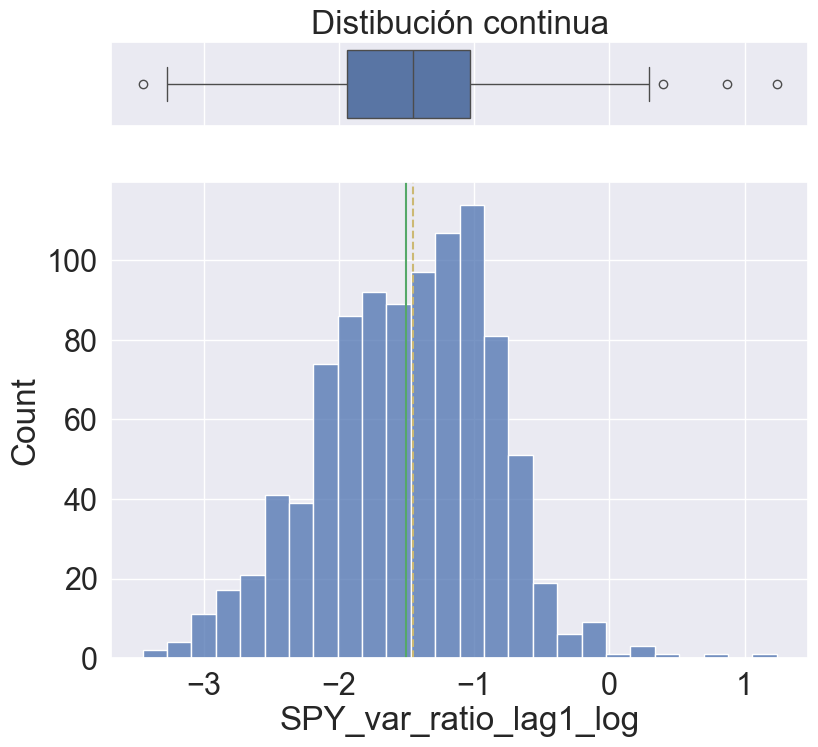

In [20]:
# Visualizar columna
col = 'SPY_var_ratio_lag1_log'
pintar_columna(df_clean[col])

In [21]:
# Tabla de Correlaciones
top_correlaciones(df=df_clean, top_n=30)

,Variable A,Variable B,correlation
770,AUDUSD_sma15_pct_diff_sma50_lag1,USDCAD_sma15_pct_diff_sma50_lag1,0.833161
576,USDCHF_sma15_pct_diff_sma50_lag1,EURUSD_sma15_pct_diff_sma50_lag1,0.785197
1385,GBPUSD_Close_position_lag1,GBPUSD_return_lag1,0.771052
1332,EURUSD_Close_position_lag1,EURUSD_return_lag1,0.762917
4850,USDCAD_acceleration_lag1_yeo,USDCAD_return_lag1_yeo,0.756640
1439,USDJPY_Close_position_lag1,USDJPY_return_lag1,0.755493
2842,USDCHF_var_20_lag1_log,EURUSD_var_20_lag1_log,0.750390
542,USDCHF_range10_position_lag1,EURUSD_range10_position_lag1,0.745823
1273,SPY_acceleration_lag1,SPY_return_lag1,0.742440
1592,USDCHF_Close_position_lag1,EURUSD_Close_position_lag1,0.737271


## Analisis de labels

In [22]:
simbolo_objetivo = 'EURUSD'
# Cargar fichero de precios
df = cargar_datos_clean()
df = remover_pares_restantes(df,simbolo_objetivo)

# Separar datos de entrenamiento y test  
ultima_fecha = df.index.max()
df_train, df_live = separar_datos_live(df=df, fecha=ultima_fecha)

# Se crea la variable categorica a partir del dataset de entrenamiento
# Variable objetivo: se crea variable categorica por cuantiles
objetivo = f"{simbolo_objetivo}_return"
objetivo_cat = f"{objetivo}_cat"

df_train, tabla_bins = categorizar_en_cuantiles(
    df_train, 
    columna=objetivo, 
    num_cuantiles=3, 
    quitar_original=True
    )


print(f"\n--- Rangos por Categoría para el ticker {simbolo_objetivo} ---")
print(tabla_bins)


--- Rangos por Categoría para el ticker EURUSD ---
   categoria  lim_inferior  lim_superior
0          1     -0.042661     -0.004675
1          2     -0.004675      0.004651
2          3      0.004651      0.044001


In [23]:
df_train[objetivo_cat].value_counts()

EURUSD_return_cat
1    322
2    322
3    322
Name: count, dtype: int64

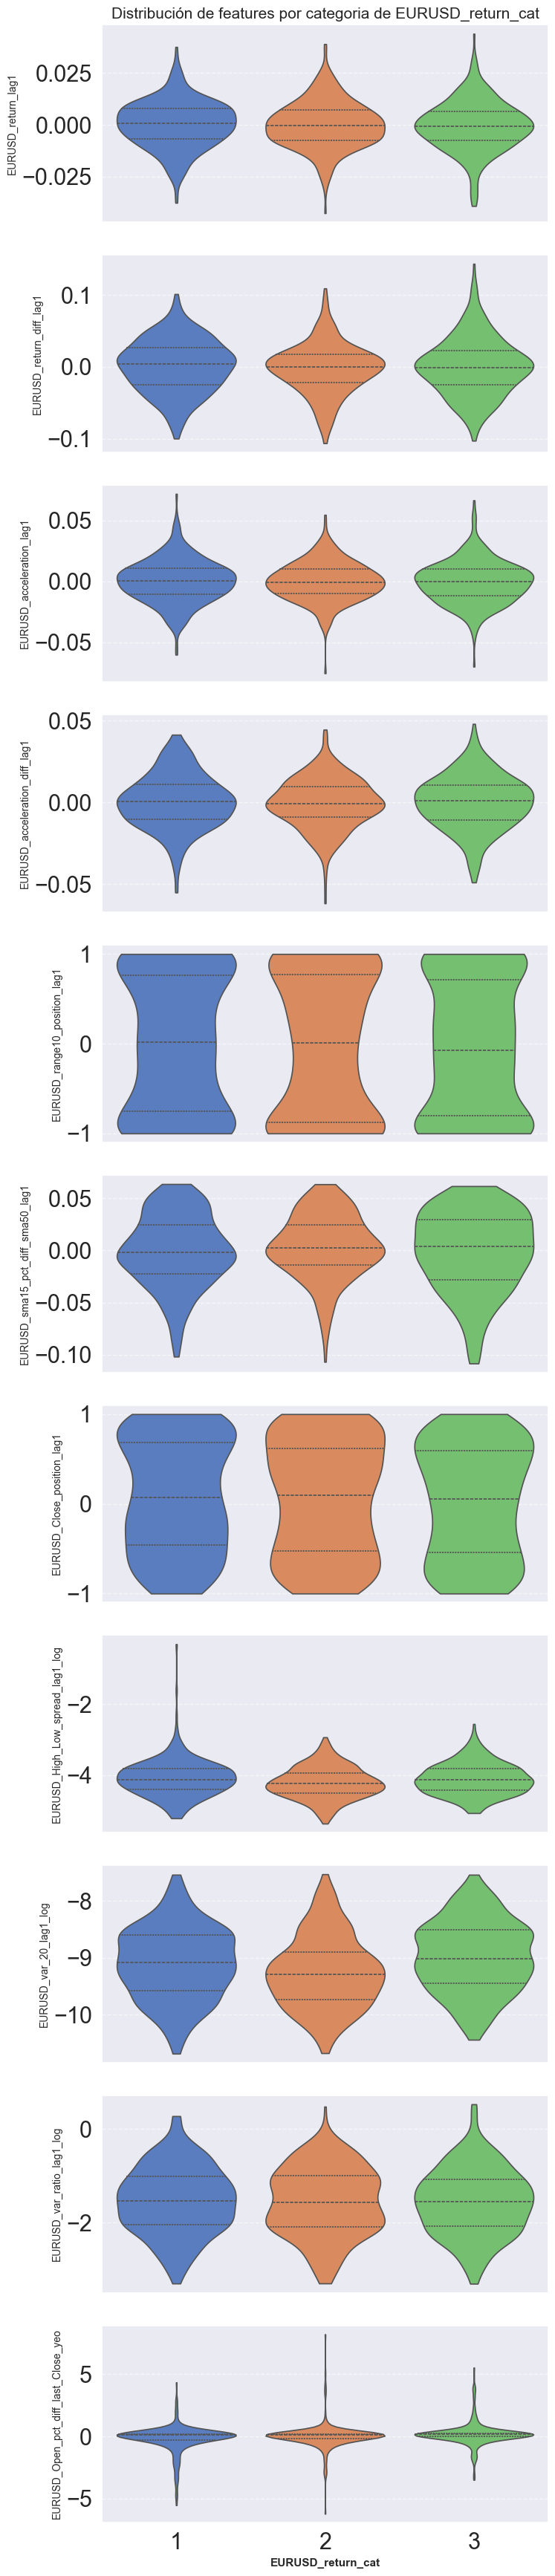

In [24]:
# Violin plot
# Identificar las variables numéricas excluyendo la variable objetivo
target_col = objetivo_cat
numeric_cols = df_train.select_dtypes(include=["number"]).columns.tolist()

# Asegurar que la columna objetivo no esté en la lista
numeric_cols = [col for col in numeric_cols if col != target_col]

# Filtrar por grupo de variables
cadena = "EURUSD"
columnas = encontrar_columnas(columnas_target=numeric_cols, cadena=cadena)

pintar_violin_plots(
    df=df_train,
    numeric_cols=columnas,
    target_col=target_col
)